In [1]:
#run this everytime an edit is made in utils.py so that we can use the helper functions in this Python Notebook
import importlib
import hw7utils
importlib.reload(hw7utils)

<module 'hw7utils' from '/Users/ivychan/finm-367/finm-367-groupc/ivy-work/hw7/hw7utils.py'>

# Forecasting SPY

In this exercise, we build forecast regressions for SPY returns using multiple valuation signals. We then convert these forecasts into investment strategies and evaluate their performance.

A key focus is the distinction between **in-sample** and **out-of-sample** forecasting. In-sample results are biased because the model has seen the data it is predicting. Out-of-sample results use only information available at the time of the forecast, giving a more realistic assessment.

### Data

Use the data in `data/spy_forecasting_data.xlsx`.

* `spy returns` - monthly total returns for SPY
* `risk-free rate` - monthly risk-free rate (`T3M`)
* `signals` - valuation signals: `DP`, `EP`, `CAPE`, `BP`, `T10YR`, `CREDIT`, `VIX`

The frequency is monthly (`FREQ = 12`).

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

from hw7utils import (summary_stats, make_ols, make_rf, make_nn, lag_align, expanding_mean_forecast,
                      insample_forecasts, oos_forecasts, strategy_returns, r2_insample, r2_oos, plot_cumulative)

warnings.filterwarnings('ignore', category=UserWarning)
pd.options.display.float_format = '{:.4f}'.format

In [3]:
FILEPATH = 'spy_forecasting_data.xlsx'
FREQ = 12

SHEET_SPY = 'spy returns'
rets = pd.read_excel(FILEPATH, sheet_name=SHEET_SPY)
rets.set_index('date', inplace=True)

SHEET_RF = 'risk-free rate'
rf = pd.read_excel(FILEPATH, sheet_name=SHEET_RF)
rf.set_index('date', inplace=True)

SHEET_SIGNALS = 'signals'
sigs = pd.read_excel(FILEPATH, sheet_name=SHEET_SIGNALS)
sigs.set_index('date', inplace=True)

display(sigs.tail(3).style.format('{:,.2f}').format_index('{:%Y-%m-%d}'))

,DP,EP,CAPE,BP,T10YR,CREDIT,VIX
date,,,,,,,
2025-08-31,1.20,3.73,36.21,18.90,4.23,174.16,15.36
2025-09-30,1.17,3.60,37.38,18.30,4.15,164.17,16.28
2025-10-31,1.14,3.52,38.15,17.89,4.08,167.25,17.44


### Timing Convention

We estimate a forecast regression:

$$r_{t+1} = \alpha + \boldsymbol{\beta}' \boldsymbol{x}_t + \epsilon_{t+1}$$

The signals at time $t$ predict returns at $t+1$. To implement this in pandas:
- **Shift** the signals forward one period (`.shift()`) to create a lagged version.
- Align the lagged signals with returns so that pandas date-matching gives us the correct lag.

Date the forecast by the period being forecasted, not the period it was calculated.

***

# 1. In-Sample Forecast Regressions

### 1.1

Create a lagged version of the signals and align it with SPY returns.

Build in-sample forecasts using the following models:
* `Mean` - the expanding mean of SPY returns (shifted one period)
* `DP` - univariate regression on Dividend-Price ratio
* `EP` - univariate regression on Earnings-Price ratio
* `ALL` - multivariate regression on all available signals

Plot the forecasted returns over time for all models.

In-sample: 1993-03-31 to 2025-10-31 (392 months)


,DP,EP,ALL
R-squared,0.0068,0.0065,0.0520


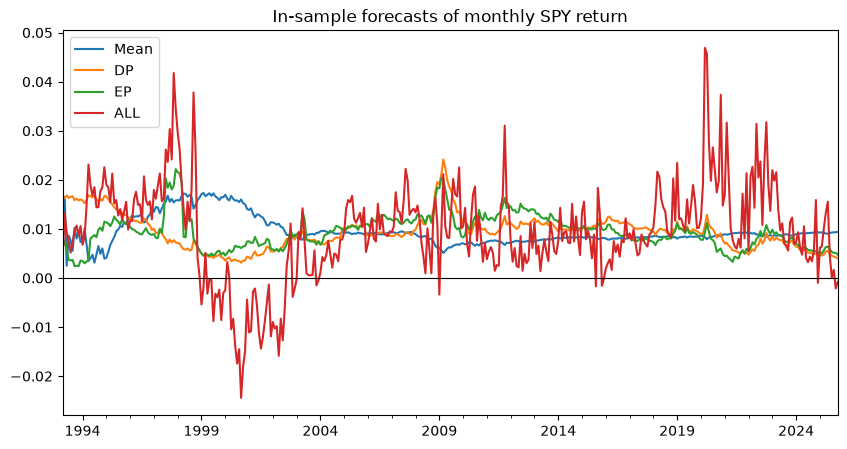

In [4]:
#lagged signals: row t+1 holds x_t, so pandas date-matching pairs x_t with r_{t+1}
spy, sigs_lag = lag_align(rets['SPY'], sigs)
SIGNALS = list(sigs.columns)

SPECS_OLS = {
    'DP':  (['DP'], make_ols),
    'EP':  (['EP'], make_ols),
    'ALL': (SIGNALS, make_ols),
}

fcst_is = pd.concat([expanding_mean_forecast(rets['SPY']).rename('Mean'),
                     insample_forecasts(spy, sigs_lag, SPECS_OLS)], axis=1).loc[spy.index]

print(f'In-sample: {spy.index[0].date()} to {spy.index[-1].date()} ({len(spy)} months)')
display(r2_insample(spy, fcst_is.drop(columns='Mean')).to_frame().T)

ax = fcst_is.plot(figsize=(10, 5), title='In-sample forecasts of monthly SPY return')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('')
plt.show()

> **In-sample forecasts (Mar 1993 - Oct 2025, 392 months).**
>
> | | DP | EP | ALL |
> |---|---|---|---|
> | In-sample $R^2$ | 0.7% | 0.7% | 5.2% |
>
> - `Mean` is the expanding mean of SPY through $t$. It is noisy for the first few years and then settles near 0.9% per month. It is the only one of the four series that is not fit to the full sample.
> - `DP` and `EP` forecasts move slowly with the valuation ratios. They are high in the early 1990s and around 2009, when valuations were cheap, and low in the late 1990s and recent years. They stay positive throughout, roughly between 0.25% and 2.4% per month.
> - `ALL` swings much more widely, from about -2.4% to +4.7% per month, and is negative in 13% of months. Most of those months are 1999-2003, and its biggest spike comes in 2020, when VIX jumped. Adding VIX, credit spreads and rates lets the regression react to stress periods, but it also gives it 7 slopes to fit to noise.

### 1.2

Build investment strategies from the forecasts using:

$$w_t = 100 \cdot \hat{r}_{t+1}$$

The strategy return is:

$$r^{\text{strategy}}_{t+1} = w_t \cdot r^{\text{SPY}}_{t+1}$$

Also include a `Passive` strategy that simply holds SPY ($w_t = 1$).

Report:
* Annualized performance metrics (mean, vol, Sharpe) for all strategies
* Correlation matrix of strategy returns
* Cumulative return plot (log scale)

,Mean,Vol,Sharpe,Min,5th Pct,Max Drawdown
Passive,0.1132,0.1477,0.7665,-0.1652,-0.0695,-0.5080
Mean,0.1023,0.1501,0.6816,-0.2327,-0.0695,-0.5169
DP,0.1215,0.1557,0.7805,-0.2274,-0.0596,-0.6608
EP,0.1208,0.1612,0.7492,-0.2191,-0.0609,-0.6519
ALL,0.2199,0.2662,0.8260,-0.5844,-0.0689,-0.6473


,Passive,Mean,DP,EP,ALL
Passive,1.0000,0.9479,0.9145,0.9318,0.6799
Mean,0.9479,1.0000,0.7814,0.8515,0.5945
DP,0.9145,0.7814,1.0000,0.9491,0.6998
EP,0.9318,0.8515,0.9491,1.0000,0.7045
ALL,0.6799,0.5945,0.6998,0.7045,1.0000


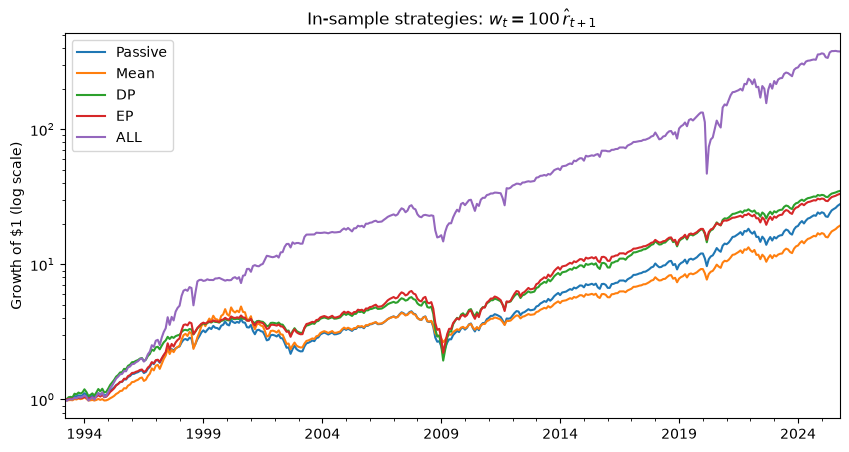

In [5]:
strats_is = strategy_returns(fcst_is, spy)

display(summary_stats(strats_is, FREQ))
display(strats_is.corr())

plot_cumulative(strats_is, 'In-sample strategies: $w_t = 100\\,\\hat r_{t+1}$')
plt.show()

> **In-sample strategy performance (annualized).**
>
> | | Passive | Mean | DP | EP | ALL |
> |---|---|---|---|---|---|
> | Mean | 11.3% | 10.2% | 12.2% | 12.1% | 22.0% |
> | Vol | 14.8% | 15.0% | 15.6% | 16.1% | 26.6% |
> | Sharpe | 0.77 | 0.68 | 0.78 | 0.75 | 0.83 |
> | Max drawdown | -51% | -52% | -66% | -65% | -65% |
>
> Sharpe here is mean / vol of the strategy's total return, so it is comparable across strategies but not an excess-return Sharpe.
>
> - `DP`, `EP` and `Mean` have correlations of 0.91-0.95 with Passive. `ALL` is the only distinct strategy, with a correlation of 0.68 with Passive.
> - `ALL` has the highest mean and Sharpe, but it gets there with much more leverage. Its worst month is -58%, against -17% for Passive.

### 1.3

Interpret the results. Which signal appears most useful? How do the active strategies compare to Passive in terms of Sharpe ratio? Are the active strategies highly correlated with each other?

In [6]:
#weights implied by the forecasts (w_t = 100 * r_hat)
display((100 * fcst_is).describe().T[['mean', 'std', 'min', 'max']])
display((100 * fcst_is).lt(0).mean().rename('Share of months short').to_frame().T)

,mean,std,min,max
Mean,0.9509,0.2887,0.2497,1.7328
DP,0.9431,0.3510,0.3125,2.4142
EP,0.9431,0.3427,0.2398,2.2193
ALL,0.9431,0.9722,-2.4432,4.6888


,Mean,DP,EP,ALL
Share of months short,0.0000,0.0000,0.0000,0.1327


> - **Most useful signal.** In-sample, `ALL` wins on both $R^2$ (5.2%) and Sharpe (0.83). Of the single signals, `DP` is slightly better than `EP` (Sharpe 0.78 vs 0.75), but both have $R^2$ below 1%, which is economically very little predictability.
> - **Against Passive.** The gains are small. `DP` adds about 0.01 of Sharpe over Passive and `EP` slightly underperforms it. Even `ALL`, with 7 regressors fit on the full sample, beats Passive by only about 0.06. `Mean` underperforms Passive (0.68 vs 0.77) because it scales exposure by the noisy early-sample average.
> - **Correlation.** The `DP`, `EP` and `Mean` strategies are never short and average a weight of about 0.94, so they are essentially Passive with exposure that varies over time. That is why they correlate 0.91-0.95 with Passive. `DP` and `EP` correlate 0.95 with each other, and `Mean` is a bit less similar to them (0.78 with `DP`, 0.85 with `EP`). `ALL` is short in 13% of months and has weights from -2.4 to 4.7, so it is the only meaningfully different strategy, with correlations of about 0.6-0.7.
> - These are upper bounds. The coefficients use data from the whole sample, so every forecast benefits from look-ahead.

***

# 2. Out-of-Sample Forecasting

The in-sample results are biased. Now re-do the forecast regressions using an **expanding window** approach so that each forecast only uses data available at the time.

At each date $t$, estimate the regression using data from the start of the sample through $t$, then form the forecast for $t+1$.

Use a burn-in period of **5 years** (`BURN_YRS = 5`) before generating the first forecast.

### 2.1

Implement the out-of-sample expanding-window forecasts for the same models: `Mean`, `DP`, `EP`, and `ALL`.

Plot the OOS forecasts over time.

OOS: 1998-03-31 to 2025-10-31 (332 months)


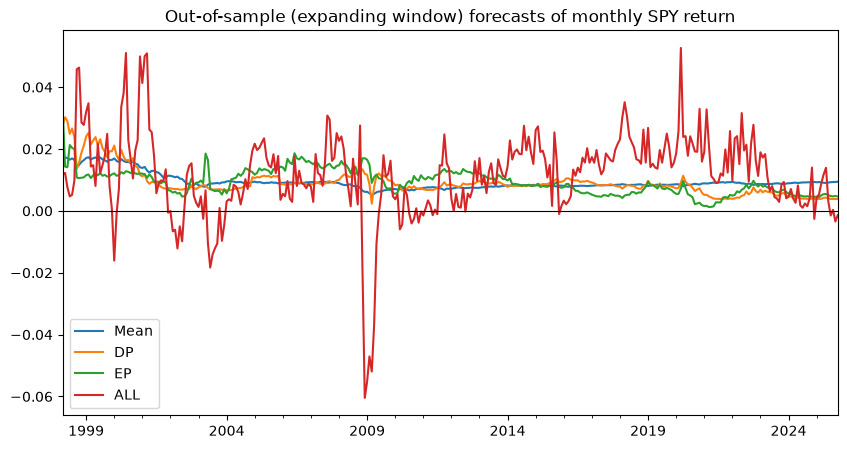

In [7]:
BURN_YRS = 5
BURN = BURN_YRS * FREQ

fcst_oos = oos_forecasts(spy, sigs_lag, sigs, SPECS_OLS, BURN)
fcst_oos.insert(0, 'Mean', expanding_mean_forecast(rets['SPY']).loc[fcst_oos.index])

print(f'OOS: {fcst_oos.index[0].date()} to {fcst_oos.index[-1].date()} ({len(fcst_oos)} months)')
ax = fcst_oos.plot(figsize=(10, 5), title='Out-of-sample (expanding window) forecasts of monthly SPY return')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('')
plt.show()

> **OOS forecasts (Mar 1998 - Oct 2025, 332 months after the 60-month burn-in).**
>
> - `DP` and `EP` start high, around 2.5-3% per month, because the first regressions use only the 1993-98 bull market. After about 2003 they converge toward the expanding mean and stay smooth, drifting as the estimated slope changes with each new observation.
> - `ALL` is far more erratic than its in-sample version. With 8 coefficients re-estimated every month on a short sample, it jumps to about +5% in 1999-2001 and again in 2020. Around the 2008-09 crisis it moves from a large long position in Oct 2008 (forecast about +2.8%) to forecasts of about -5% to -6% per month from Dec 2008 to Mar 2009. In other words, it was short right into the March 2009 rebound.

### 2.2

Build the investment strategies from the OOS forecasts (using $w_t = 100 \cdot \hat{r}_{t+1}$) and report the same performance metrics as in Section 1.

Report:
* OOS $R^2$ for each model, using the expanding mean as the null forecast:

$$R^2_{\text{OOS}} = 1 - \frac{\text{MSE}_{\text{forecast}}}{\text{MSE}_{\text{null}}}$$

* Annualized performance metrics
* Cumulative returns (log scale)
* Correlation matrix

,DP,EP,ALL
OOS R-squared,-0.0055,-0.0040,-0.0611


,Mean,Vol,Sharpe,Min,5th Pct,Max Drawdown
Passive,0.0972,0.1533,0.6342,-0.1652,-0.0765,-0.5080
Mean,0.0820,0.1512,0.5421,-0.2327,-0.0730,-0.5169
DP,0.0809,0.1659,0.4876,-0.3354,-0.0659,-0.5518
EP,0.0831,0.1653,0.5027,-0.2817,-0.0688,-0.6431
ALL,0.1459,0.3557,0.4101,-0.6566,-0.1106,-0.8102


,Passive,Mean,DP,EP,ALL
Passive,1.0000,0.9520,0.8971,0.9215,0.5298
Mean,0.9520,1.0000,0.9516,0.9091,0.5854
DP,0.8971,0.9516,1.0000,0.9412,0.5268
EP,0.9215,0.9091,0.9412,1.0000,0.4302
ALL,0.5298,0.5854,0.5268,0.4302,1.0000


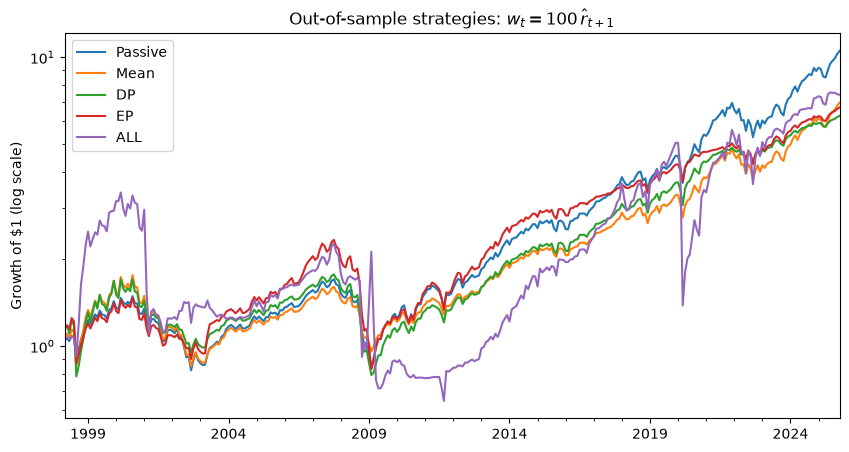

In [8]:
display(r2_oos(spy, fcst_oos.drop(columns='Mean'), fcst_oos['Mean']).to_frame().T)

strats_oos = strategy_returns(fcst_oos, spy)
display(summary_stats(strats_oos, FREQ))
display(strats_oos.corr())

plot_cumulative(strats_oos, 'Out-of-sample strategies: $w_t = 100\\,\\hat r_{t+1}$')
plt.show()

> **OOS $R^2$ (relative to the expanding mean):** `DP` -0.55%, `EP` -0.40%, `ALL` -6.1%.
>
> **OOS strategy performance (annualized, Mar 1998 - Oct 2025):**
>
> | | Passive | Mean | DP | EP | ALL |
> |---|---|---|---|---|---|
> | Mean | 9.7% | 8.2% | 8.1% | 8.3% | 14.6% |
> | Vol | 15.3% | 15.1% | 16.6% | 16.5% | 35.6% |
> | Sharpe | 0.63 | 0.54 | 0.49 | 0.50 | 0.41 |
> | Max drawdown | -51% | -52% | -55% | -64% | -81% |
>
> - Every OOS $R^2$ is negative, so no model forecasts better than the historical mean.
> - Every active strategy has a lower Sharpe than Passive. `ALL` is the worst: its weights reach 5.3 just before Mar 2020 (a -66% month), and its max drawdown is -81%.
> - Correlations follow the same pattern as in-sample. `DP`, `EP` and `Mean` correlate about 0.9 with Passive, while `ALL` correlates 0.43-0.59 with the others.

### 2.3

Compare the in-sample and out-of-sample results. Do the signals that looked good in-sample still look good out-of-sample? Is the OOS $R^2$ positive for any model?

,IS R-squared,OOS R-squared,IS Sharpe (OOS window),OOS Sharpe
Passive,NaN,NaN,0.6342,0.6342
Mean,NaN,NaN,0.5421,0.5421
DP,0.0068,-0.0055,0.6273,0.4876
EP,0.0065,-0.0040,0.5978,0.5027
ALL,0.0520,-0.0611,0.6975,0.4101


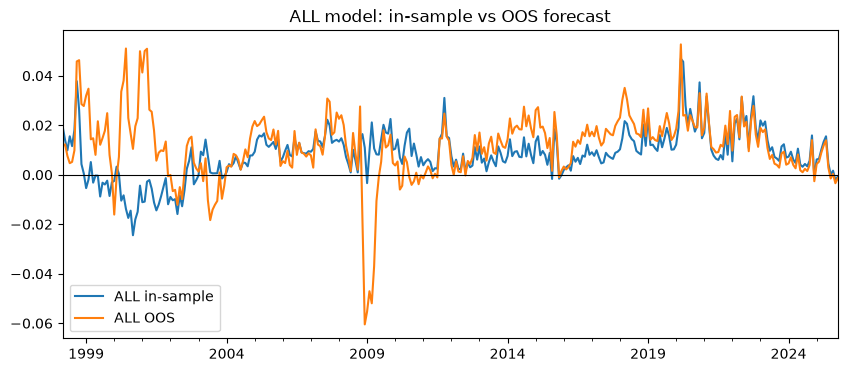

In [9]:
#in-sample stats restricted to the OOS window, so the comparison is over the same months
compare = pd.DataFrame({
    'IS R-squared': r2_insample(spy, fcst_is.drop(columns='Mean')),
    'OOS R-squared': r2_oos(spy, fcst_oos.drop(columns='Mean'), fcst_oos['Mean']),
    'IS Sharpe (OOS window)': summary_stats(strats_is.loc[strats_oos.index], FREQ)['Sharpe'],
    'OOS Sharpe': summary_stats(strats_oos, FREQ)['Sharpe'],
}).reindex(['Passive', 'Mean', 'DP', 'EP', 'ALL'])
display(compare)

ax = pd.concat([fcst_is['ALL'].rename('ALL in-sample'), fcst_oos['ALL'].rename('ALL OOS')], axis=1).loc[fcst_oos.index].plot(figsize=(10, 4), title='ALL model: in-sample vs OOS forecast')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('')
plt.show()

> | | IS $R^2$ | OOS $R^2$ | IS Sharpe (same window) | OOS Sharpe |
> |---|---|---|---|---|
> | DP | 0.7% | -0.55% | 0.63 | 0.49 |
> | EP | 0.7% | -0.40% | 0.60 | 0.50 |
> | ALL | 5.2% | -6.1% | 0.70 | 0.41 |
> | Passive | | | 0.63 | 0.63 |
>
> - **No, the in-sample results do not survive.** Over the same 1998-2025 window, the in-sample `ALL` strategy would have beaten Passive (0.70 vs 0.63). Built in real time, it falls to 0.41. `DP` and `EP` drop from roughly Passive's Sharpe to about 0.5.
> - **No model has a positive OOS $R^2$.** The drop is largest for the model that looked best in-sample. `ALL` goes from +5.2% to -6.1% because 8 parameters estimated on short, expanding samples carry a lot of estimation error. The single-signal models lose less only because they had little predictability to begin with.
> - This is the standard Goyal-Welch result. Valuation ratios have some in-sample predictive power, but it is too weak and unstable to use in real time. In-sample fit mainly measures look-ahead and overfitting.

***

# 3. Extension: Machine Learning Forecasts

Compare the OLS approach with machine learning methods. Use all signals as features and compare:
* `OLS` - linear regression (same as `ALL` above)
* `Random Forest` - with `max_depth=5`, `n_estimators=100`
* `NN` - neural network (`MLPRegressor` with `hidden_layer_sizes=(50,)`)

For the neural network, standardize the features and target before training (using `StandardScaler`), and inverse-transform the predictions back to the original scale.

### 3.1

First, estimate and evaluate the ML models **in-sample** alongside OLS and the expanding mean.

Report the performance metrics and correlation of the resulting strategies. Plot the cumulative returns.

Note that the ML models may overfit. How does in-sample $R^2$ compare between OLS and the ML methods?

,OLS,Random Forest,NN
R-squared,0.0520,0.3284,0.3570


,Mean,Vol,Sharpe,Min,5th Pct,Max Drawdown
Passive,0.1132,0.1477,0.7665,-0.1652,-0.0695,-0.5080
Mean,0.1023,0.1501,0.6816,-0.2327,-0.0695,-0.5169
OLS,0.2199,0.2662,0.8260,-0.5844,-0.0689,-0.6473
Random Forest,0.5512,0.4288,1.2855,-0.0710,-0.0263,-0.1337
NN,0.7453,0.4766,1.5638,-0.1515,-0.0527,-0.2362


,Passive,Mean,OLS,Random Forest,NN
Passive,1.0000,0.9479,0.6799,0.1955,0.1949
Mean,0.9479,1.0000,0.5945,0.1660,0.1841
OLS,0.6799,0.5945,1.0000,0.3683,0.4690
Random Forest,0.1955,0.1660,0.3683,1.0000,0.7961
NN,0.1949,0.1841,0.4690,0.7961,1.0000


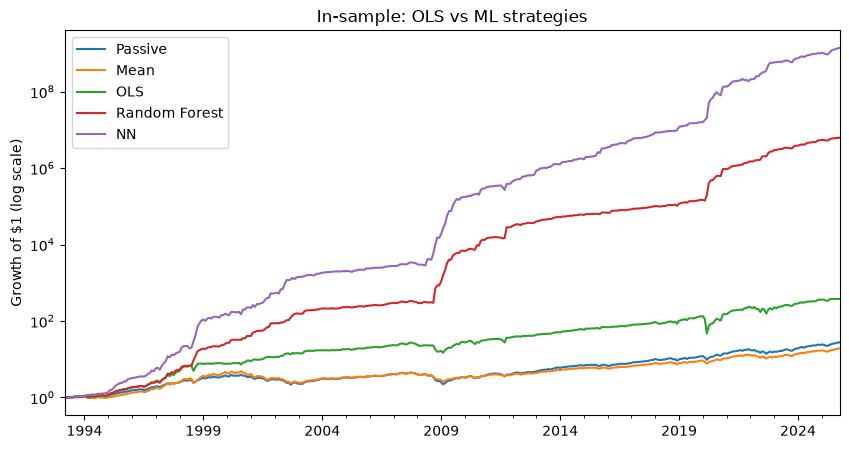

In [10]:
SPECS_ML = {
    'OLS': (SIGNALS, make_ols),
    'Random Forest': (SIGNALS, make_rf),
    'NN': (SIGNALS, make_nn),
}

fcst_ml_is = pd.concat([fcst_is['Mean'], insample_forecasts(spy, sigs_lag, SPECS_ML)], axis=1)

display(r2_insample(spy, fcst_ml_is.drop(columns='Mean')).to_frame().T)

strats_ml_is = strategy_returns(fcst_ml_is, spy)
display(summary_stats(strats_ml_is, FREQ))
display(strats_ml_is.corr())

plot_cumulative(strats_ml_is, 'In-sample: OLS vs ML strategies')
plt.show()

> **In-sample $R^2$:** OLS 5.2%, Random Forest 32.8%, NN 35.7%.
>
> | | Passive | Mean | OLS | Random Forest | NN |
> |---|---|---|---|---|---|
> | Mean | 11.3% | 10.2% | 22.0% | 55.1% | 74.5% |
> | Vol | 14.8% | 15.0% | 26.6% | 42.9% | 47.7% |
> | Sharpe | 0.77 | 0.68 | 0.83 | 1.29 | 1.56 |
> | Max drawdown | -51% | -52% | -65% | -13% | -24% |
>
> - The ML models appear to dominate. They explain about a third of the variance in monthly returns, have Sharpe ratios of 1.3-1.6, and have tiny drawdowns. Their correlation with Passive is only about 0.2, and they correlate 0.80 with each other.
> - These numbers are not credible. An $R^2$ of 33-36% for monthly equity returns is far beyond anything plausible. With 392 observations, a depth-5 forest and a 50-unit network (about 450 weights) are flexible enough to largely memorize the sample, including the crash months. They have fit noise, so the in-sample performance is mostly overfitting. The gap between OLS and the ML models measures that extra flexibility, not extra signal.

### 3.2

Now estimate the ML models **out-of-sample** using the same expanding-window approach as Section 2.

Report the same metrics. Do the ML methods outperform OLS out-of-sample? Does the in-sample advantage survive?

,OLS,Random Forest,NN
OOS R-squared,-0.0611,-0.1668,-0.5817


,Mean,Vol,Sharpe,Min,5th Pct,Max Drawdown
Passive,0.0972,0.1533,0.6342,-0.1652,-0.0765,-0.5080
Mean,0.0820,0.1512,0.5421,-0.2327,-0.0730,-0.5169
OLS,0.1459,0.3557,0.4101,-0.6566,-0.1106,-0.8102
Random Forest,-0.0458,0.3475,-0.1317,-0.9116,-0.1006,-0.9921
NN,-0.0055,0.7326,-0.0076,-2.0591,-0.2090,-1.2709


,Passive,Mean,OLS,Random Forest,NN
Passive,1.0000,0.9520,0.5298,0.2274,0.1755
Mean,0.9520,1.0000,0.5854,0.2547,0.2023
OLS,0.5298,0.5854,1.0000,0.6409,0.4310
Random Forest,0.2274,0.2547,0.6409,1.0000,0.6812
NN,0.1755,0.2023,0.4310,0.6812,1.0000


,Avg weight,Max weight,Min weight,Share short,Worst month,Worst return
Mean,0.9356,1.7328,0.5112,0.0000,1998-08-31,-0.2327
OLS,1.1530,5.2675,-6.0457,0.1235,2020-03-31,-0.6566
Random Forest,0.5323,5.5185,-8.2649,0.2108,2008-10-31,-0.9116
NN,0.5331,12.4652,-30.1756,0.3373,2008-10-31,-2.0591


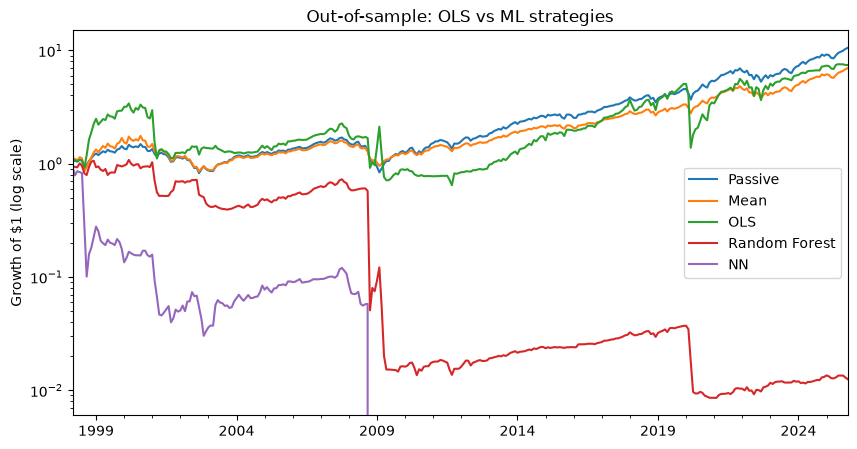

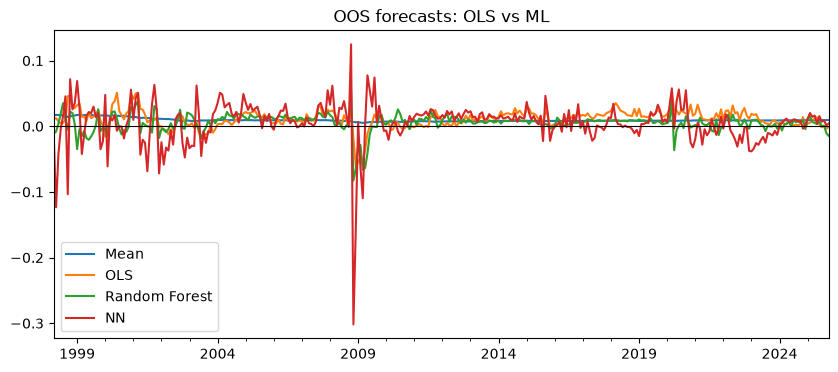

In [11]:
#slow: one Random Forest and one NN fit per month of the OOS window
fcst_ml_oos = pd.concat([fcst_oos[['Mean']], fcst_oos[['ALL']].rename(columns={'ALL': 'OLS'}),
                         oos_forecasts(spy, sigs_lag, sigs, {k: SPECS_ML[k] for k in ['Random Forest', 'NN']}, BURN)], axis=1)

display(r2_oos(spy, fcst_ml_oos.drop(columns='Mean'), fcst_ml_oos['Mean']).to_frame().T)

strats_ml_oos = strategy_returns(fcst_ml_oos, spy)
display(summary_stats(strats_ml_oos, FREQ))
display(strats_ml_oos.corr())

#implied weights, and the worst month for each strategy
weights_ml_oos = 100 * fcst_ml_oos
display(pd.DataFrame({'Avg weight': weights_ml_oos.mean(), 'Max weight': weights_ml_oos.max(),
                      'Min weight': weights_ml_oos.min(), 'Share short': weights_ml_oos.lt(0).mean(),
                      'Worst month': strats_ml_oos.drop(columns='Passive').idxmin().dt.date,
                      'Worst return': strats_ml_oos.drop(columns='Passive').min()}))

plot_cumulative(strats_ml_oos, 'Out-of-sample: OLS vs ML strategies')
plt.show()

ax = fcst_ml_oos.plot(figsize=(10, 4), title='OOS forecasts: OLS vs ML')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('')
plt.show()

> **OOS $R^2$:** OLS -6.1%, Random Forest -16.7%, NN -58.2%.
>
> | | Passive | Mean | OLS | Random Forest | NN |
> |---|---|---|---|---|---|
> | Mean | 9.7% | 8.2% | 14.6% | -4.6% | -0.6% |
> | Vol | 15.3% | 15.1% | 35.6% | 34.8% | 73.3% |
> | Sharpe | 0.63 | 0.54 | 0.41 | -0.13 | -0.01 |
>
> - **The ML methods do not beat OLS out-of-sample. They are much worse.** The ranking is the reverse of the in-sample one: the more flexible the model, the worse its OOS $R^2$ and Sharpe.
> - **The in-sample advantage does not survive.** Both ML strategies are destroyed in Oct 2008. Going into that month, the NN had a weight of about 12.5 and the forest about 5.5. With SPY down 16.5%, those positions returned -206% and -91%. The NN strategy's wealth goes negative, so its line drops off the log plot and its max drawdown below -100% is not meaningful. The forest never recovers and ends at about \$0.01. The ML models then go heavily short into the 2009 rebound.
> - The rule $w_t = 100\,\hat r_{t+1}$ has no leverage cap, so it turns forecast errors directly into position size. Noisy models produce extreme weights exactly when volatility is highest. A real implementation would cap or shrink the weights. That would limit the damage, but it would not make the forecasts any better: the OOS $R^2$ is negative for every model.
> - **Conclusion.** For monthly SPY returns, the predictable component is small enough that model flexibility mostly adds variance. The expanding mean, and Passive, remain hard to beat.

### Hints

* Use `.shift()` and `.dropna()` to create the lagged signals.
* For the expanding mean baseline: `rets[['SPY']].expanding().mean().shift(1).dropna()`
* In the OOS loop, at each time $t$, fit the model on `sigs_lag.loc[:t]` and `spy.loc[:t]`, then predict using `sigs.loc[t]` (the unlagged signal at $t$, which forecasts $t+1$).
* After the loop, shift the OOS forecasts forward one period so timestamps reflect the date being forecasted.
* For the neural network OOS, fit a new `StandardScaler` at each step using only data through $t$.
* `sklearn.ensemble.RandomForestRegressor` and `sklearn.neural_network.MLPRegressor` are the relevant imports.
* The OOS ML loop will be slow (many regressions). This is expected.